# Flow Matching on a torus: constraint timing

One sample is a point in $\mathbb{R}^3$. We learn a distribution uniform in surface area on a torus with R=3 and r=1, then compare A/B/C/D using the **same trained model and paired initial noise**.

`torus_project.py` contains the single authoritative implementation used by this notebook and the numerical tests. There are no separate preliminary A/C implementations.

By default, Run All loads the existing **20,000-point trained checkpoint** and analyses saved samples. It does not retrain or regenerate them. Set `TRAIN_FROM_SCRATCH=True` to reproduce the full training and sampling pipeline in a new run. The checkpoint is then saved immediately after training, before any plots or sampling.

### Reading guide

Read each explanation before running the following code cell. The notebook is the
experiment narrative; imported Python modules implement the reusable mathematics.
See `CODE_GUIDE.md` for the file map, tensor shapes, units and execution order.
Flow time runs from 0 to 1 and is distinct from the 24 clock hours in a load profile.

**Experiment overview:** 20,000 training points · 5,000 optimisation steps · 2,000 generated points per seed · 10 paired sampling seeds.


## Getting started · local Jupyter or Google Colab

**Read the saved outputs first.** They contain the completed experiment. Running all
cells refreshes the analysis with `TRAIN_FROM_SCRATCH = False`; no training is needed.

For **Google Colab**, upload the complete `flow_matching_project` folder to
**My Drive**, including the Python modules, manifests and `outputs/` directory.
Open this notebook in Colab and choose **Runtime → Run all**. The next cell mounts
Google Drive only when needed and locates the project. If you use another location,
set `PROJECT_DIRECTORY` to its full path. Uploading only the `.ipynb` is insufficient.
A CPU runtime is sufficient for analysing the saved experiments.

For **local Jupyter**, open the notebook from the project folder using the environment
in `README.md`. The setup preserves installed packages and installs only missing
analysis dependencies in Colab. Historical and validation versions are documented
in the two requirements files; runtime versions may differ in Colab.


In [1]:
# Locate the complete project before importing its local Python modules.
from pathlib import Path
import os
import sys
import importlib.util
import subprocess

PROJECT_DIRECTORY = ""  # Optional full path; leave empty for automatic detection.
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    try:
        IN_COLAB = importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        IN_COLAB = False

required = ("torus_project.py", "load_profile_project.py", "notebook_utils.py",
            "torus_run.json", "load_run.json", "outputs")

def is_project(path):
    """Recognise the supplied project by its modules and saved-run manifests."""
    return all((path / name).exists() for name in required)

candidates = ([Path(PROJECT_DIRECTORY).expanduser()] if PROJECT_DIRECTORY.strip()
              else [Path.cwd(), Path.cwd() / "flow_matching_project",
                    Path("/content/flow_matching_project"),
                    Path("/content/drive/MyDrive/flow_matching_project")])
if IN_COLAB and not any(is_project(p) for p in candidates) and not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")


project_root = next((p.resolve() for p in candidates if is_project(p)), None)
if project_root is None:
    raise FileNotFoundError(
        "Complete project folder not found. Upload the whole flow_matching_project "
        "folder to My Drive, or set PROJECT_DIRECTORY to its full path and rerun.")
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

packages = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
            "matplotlib": "matplotlib", "torch": "torch", "jinja2": "jinja2"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if not IN_COLAB:
        raise ImportError("Install requirements-audit.txt in your local environment.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Project ready:", project_root)


Project ready: /Users/mariadomarvieira/Desktop/flow_matching_project


In [2]:
# Configure the fixed course protocol and seed training-data generation. The
# manifest selects the saved experiment; it does not change the network weights.
from pathlib import Path
from datetime import datetime
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torus_project import (
    FlowMatchingNetwork,
    sample_torus,
    sample_abcd,
    reference_torus,
    measure,
    sw1,
    supplementary_analysis,
)

from notebook_utils import COLORS, configure_plots, show_table, show_summary
configure_plots()
torch.set_num_threads(4)
TRAIN_FROM_SCRATCH = False
training_config = dict(
    seed=42,
    training_samples=20000,
    iterations=5000,
    batch_size=512,
    learning_rate=1e-3,
    gradient_clip=1.0,
    optimizer="Adam",
    architecture="4 -> 256 x 4 (SiLU) -> 3",
    R=3.0,
    r=1.0,
)
project_config = json.loads(Path("torus_run.json").read_text())
run_dir = Path(project_config["run_dir"])
checkpoint_path = Path(project_config["checkpoint"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(training_config["seed"])
torch.manual_seed(training_config["seed"])
data = sample_torus(training_config["training_samples"])
print("Training dataset:", data.shape, "| Device:", device)

Training dataset: (20000, 3) | Device: cpu


## 1. Training distribution and model

Theta is uniform on [0,2π). Phi is sampled by rejection with acceptance probability $(R+r\cos\phi)/(R+r)$, giving density $p(\phi)=(R+r\cos\phi)/(2\pi R)$, not uniform angles.

The model has four hidden layers of width 256 and SiLU activations. Training uses 20,000 points, 5,000 iterations, batch size 512, Adam at 0.001 and gradient clipping at 1. Linear Flow Matching uses $x_t=(1-t)x_0+tx_1$, standard Gaussian $x_0$, uniform t, and target velocity $x_1-x_0$.

For the historical checkpoint, training settings are recovered from the executed notebook; dependency versions are documented in `requirements.txt`. Original optimizer/RNG state was not saved and cannot be reconstructed. The enriched checkpoint preserves the original weights and records this limitation. New training runs save optimizer and RNG states too.

In [3]:
# Train only when explicitly requested; otherwise load the documented checkpoint.
# All later strategies use these same weights.
model = FlowMatchingNetwork().to(device)
if TRAIN_FROM_SCRATCH:
    output_dir = Path("outputs/torus_abcd")
    run_dir = output_dir / ("run_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    run_dir.mkdir(parents=True)
    checkpoint_path = run_dir / "model.pt"
    tensor = torch.tensor(data, dtype=torch.float32, device=device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=training_config["learning_rate"]
    )
    losses = []
    model.train()
    for iteration in range(training_config["iterations"]):
        x1 = tensor[
            torch.randint(len(tensor), (training_config["batch_size"],), device=device)
        ]
        x0 = torch.randn_like(x1)
        t = torch.rand(len(x1), 1, device=device)
        loss = (model((1 - t) * x0 + t * x1, t) - (x1 - x0)).square().mean()
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), training_config["gradient_clip"]
        )
        optimizer.step()
        losses.append(loss.item())
        if (iteration + 1) % 500 == 0:
            print(f"Iteration {iteration+1}: loss={loss.item():.6f}")
    # Save immediately after training, before plots or inference.
    torch.save(
        dict(
            model_state_dict=model.state_dict(),
            losses=losses,
            training_samples=len(data),
            training_config=training_config,
            versions={
                p: importlib.metadata.version(p)
                for p in ["torch", "numpy", "pandas", "matplotlib"]
            },
            python_version=platform.python_version(),
            optimizer_state_dict=optimizer.state_dict(),
            torch_rng_state=torch.get_rng_state(),
            numpy_rng_state=np.random.get_state(),
            cuda_rng_states=(
                torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
            ),
        ),
        checkpoint_path,
    )
else:
    # Only load a trusted checkpoint supplied with this project.
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    assert checkpoint["training_samples"] == 20000
    assert checkpoint["training_config"] == training_config
    model.load_state_dict(checkpoint["model_state_dict"])
    losses = checkpoint["losses"]
model.eval()
model_device = next(model.parameters()).device
model_dtype = next(model.parameters()).dtype
print("Checkpoint:", checkpoint_path.as_posix())
print("Training iterations:", len(losses), "| Training points:", len(data))

Checkpoint: outputs/torus_abcd/run_20260928_190723_530525/model_documented.pt
Training iterations: 5000 | Training points: 20000


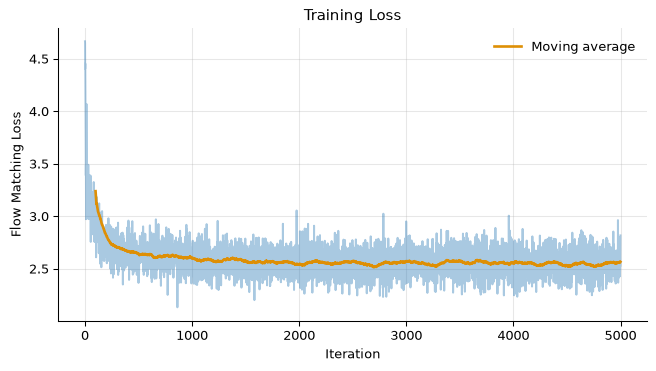

In [4]:
# Plot the original stochastic batch loss and a 100-iteration moving average.
# Smoothing aids readability; it does not change training or checkpoint selection.
plt.figure(figsize=(8, 4))

plt.plot(losses, alpha=0.4)

# Moving average to make the trend easier to see
window = 100
moving_average = np.convolve(losses, np.ones(window) / window, mode="valid")

plt.plot(
    range(window - 1, len(losses)), moving_average, linewidth=2, label="Moving average"
)

plt.xlabel("Iteration")
plt.ylabel("Flow Matching Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 2. One model, four sampling strategies

With $\rho=\sqrt{x^2+y^2}$, feasibility is $h=(\rho-R)^2+z^2-r^2=0$.

- **A:** ordinary Euler integration, without correction.
- **B:** after each Euler step, $x\leftarrow x-0.3h\nabla h/(\|\nabla h\|^2+10^{-8})$, evaluated at the updated point.
- **C:** exact surface projection after each Euler step.
- **D:** a single projection of A's final result.

All methods share the trained weights, initial noise and Euler schedule within each seed. C versus D directly compares repeated and terminal use of the same hard projection. Their intermediate trajectories then differ as a consequence of constraint timing.

On the z-axis the gradient is undefined, so the implementation uses the +x radial direction. On the tube centreline, projection is nonunique; the outer side is chosen deterministically. These degenerate cases are tested explicitly.

In [5]:
# Use paired noise across A/B/C/D and independent surface-uniform references. Unit
# projection directions make the SW1 scale interpretable.
N_SAMPLES, N_STEPS = 2000, 100
SEEDS = list(range(10))
directions = np.random.default_rng(2026).normal(size=(3, 128))
directions /= np.linalg.norm(directions, axis=0, keepdims=True)
if TRAIN_FROM_SCRATCH:
    rows, baseline_sw1 = [], []
    for seed in SEEDS:
        generator = torch.Generator(device=model_device).manual_seed(seed)
        x0 = torch.randn(
            N_SAMPLES, 3, generator=generator, device=model_device, dtype=model_dtype
        )
        reference = reference_torus(N_SAMPLES, np.random.default_rng(10000 + seed))
        other_reference = reference_torus(
            N_SAMPLES, np.random.default_rng(20000 + seed)
        )
        baseline_sw1.append(sw1(other_reference, reference, directions))
        samples = {
            k: v.cpu().numpy() for k, v in sample_abcd(model, x0, N_STEPS).items()
        }
        for method, points in samples.items():
            rows.append(
                dict(seed=seed, method=method, **measure(points, reference, directions))
            )
        np.savez_compressed(
            run_dir / f"samples_seed_{seed}.npz", reference=reference, **samples
        )
        print("Completed seed", seed)
    pd.DataFrame(rows).to_csv(run_dir / "metrics.csv", index=False)
    config = dict(
        n_samples=N_SAMPLES,
        n_steps=N_STEPS,
        seeds=SEEDS,
        training_samples=len(data),
        training_config=training_config,
        soft_strength=0.3,
        soft_eps=1e-8,
        R=3.0,
        r=1.0,
        feasible_tolerance=1e-3,
        sw_directions=128,
        sw_direction_seed=2026,
        checkpoint=checkpoint_path.as_posix(),
        path_base="project root",
        reference_reference_sw1=baseline_sw1,
    )
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))
else:
    config = json.loads((run_dir / "config.json").read_text())
    baseline_sw1 = config["reference_reference_sw1"]
frame = pd.read_csv(run_dir / "metrics.csv")
assert set(frame["seed"]) == set(SEEDS) and len(frame) == 40
show_summary(frame, {
    "mean_abs_h": "Mean |h| ↓", "mean_surface_distance": "Surface distance ↓",
    "feasible_fraction": "Feasible (%) ↑", "sliced_w1": "SW1 ↓"},
    "Primary torus comparison · mean ± sample SD across 10 sampling seeds",
    percentages=("feasible_fraction",))
with np.load(run_dir / "samples_seed_0.npz") as saved:
    plot_reference = saved["reference"].copy()
    plot_samples = {k: saved[k].copy() for k in "ABCD"}
summary = [
    dict(method=m, metric=k, mean=g[k].mean(), std=g[k].std())
    for m, g in frame.groupby("method")
    for k in ["mean_abs_h", "mean_surface_distance", "feasible_fraction", "sliced_w1"]
]
print(
    "Reference/reference SW1:",
    np.mean(baseline_sw1),
    "+/-",
    np.std(baseline_sw1, ddof=1),
)
print("Results:", run_dir.as_posix())

,Mean |h| ↓,Surface distance ↓,Feasible (%) ↑,SW1 ↓
Method,,,,
A,0.0931 ± 0.0019,0.0472 ± 0.0010,0.79 ± 0.21,0.0846 ± 0.0198
B,0.0313 ± 0.0005,0.0155 ± 0.0002,2.63 ± 0.49,0.1284 ± 0.0138
C,9.28e-08 ± 2.81e-09,4.64e-08 ± 1.40e-09,100.00 ± 0.00,0.1446 ± 0.0142
D,1.55e-07 ± 4.36e-09,7.76e-08 ± 2.18e-09,100.00 ± 0.00,0.0836 ± 0.0206


Reference/reference SW1: 0.06622076521016036 +/- 0.01947186844607379
Results: outputs/torus_abcd/run_20260928_190723_530525


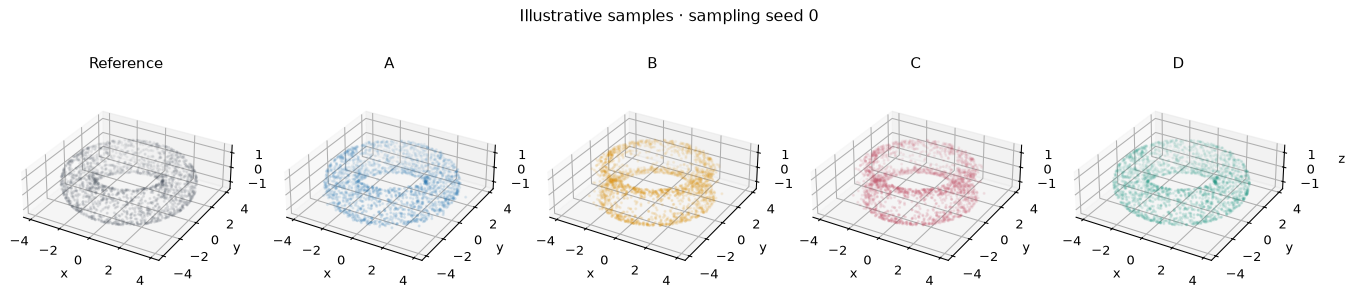

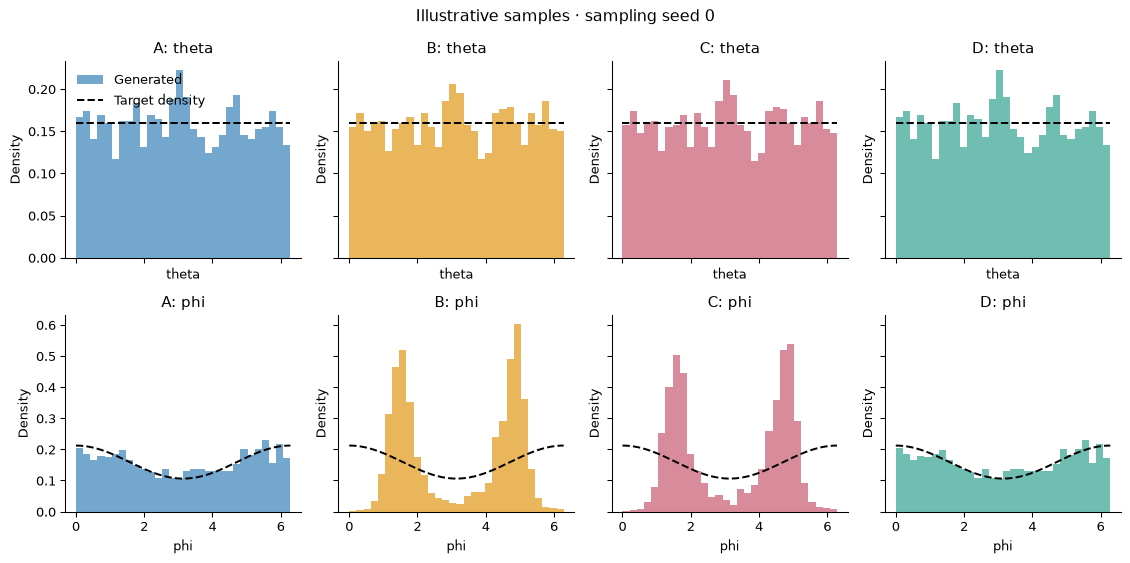

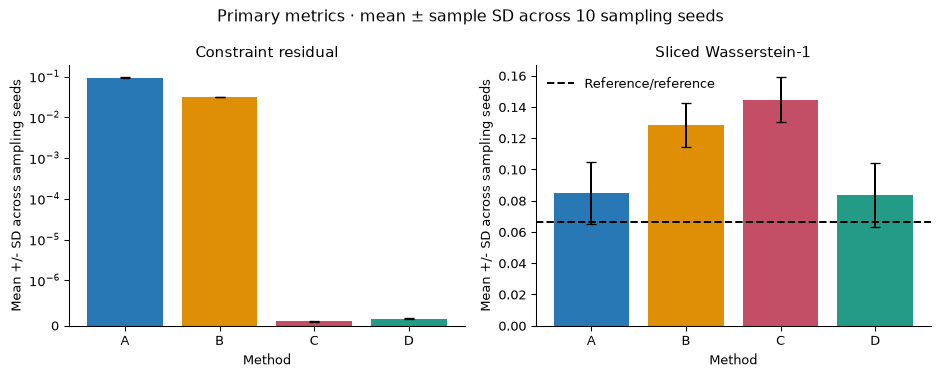

In [6]:
# Separate illustrative geometry from quantitative evidence: seed 0 supplies the
# pictures; the metric bars aggregate all ten seeds.
# Example seed 0 only; not selected as statistically representative.
from torus_project import torus_angles, R, r

fig = plt.figure(figsize=(14, 3.5))
for i, (name, points) in enumerate(
    {"Reference": plot_reference, **plot_samples}.items(), 1
):
    ax = fig.add_subplot(1, 5, i, projection="3d")
    ax.scatter(*points.T, s=2, alpha=0.35, color=COLORS[name])
    ax.set(
        xlim=(-4.5, 4.5),
        ylim=(-4.5, 4.5),
        zlim=(-1.5, 1.5),
        xlabel="x",
        ylabel="y",
        zlabel="z",
        title=name,
    )
    ax.set_box_aspect((9, 9, 3))
fig.suptitle("Illustrative samples · sampling seed 0")
fig.tight_layout()
fig.savefig(run_dir / "samples_3d.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey="row")
grid = np.linspace(0, 2 * np.pi, 400)
bins = np.linspace(0, 2 * np.pi, 31)
for col, (method, points) in enumerate(plot_samples.items()):
    theta, phi = torus_angles(points)
    for row, (angles, density, label) in enumerate(
        [
            (theta, np.full_like(grid, 1 / (2 * np.pi)), "theta"),
            (phi, (R + r * np.cos(grid)) / (2 * np.pi * R), "phi"),
        ]
    ):
        ax = axes[row, col]
        ax.hist(angles, bins=bins, density=True, alpha=0.65, color=COLORS[method], label="Generated")
        ax.plot(grid, density, "k--", label="Target density")
        ax.set(title=f"{method}: {label}", xlabel=label, ylabel="Density")
axes[0, 0].legend()
fig.suptitle("Illustrative samples · sampling seed 0")
fig.tight_layout()
fig.savefig(run_dir / "angular_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(
    axes, ["mean_abs_h", "sliced_w1"], ["Constraint residual", "Sliced Wasserstein-1"]
):
    entries = [s for s in summary if s["metric"] == metric]
    ax.bar(
        [s["method"] for s in entries],
        [s["mean"] for s in entries],
        yerr=[s["std"] for s in entries],
        capsize=4, color=[COLORS[s["method"]] for s in entries],
    )
    ax.set(title=title, xlabel="Method", ylabel="Mean +/- SD across sampling seeds")
axes[0].set_yscale("symlog", linthresh=1e-6)
axes[1].axhline(
    np.mean(baseline_sw1), color="black", linestyle="--", label="Reference/reference"
)
axes[1].legend()
fig.suptitle("Primary metrics · mean ± sample SD across 10 sampling seeds")
fig.tight_layout()
fig.savefig(run_dir / "metrics.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Angular fidelity across all 10 seeds

The target CDF on the fixed interval [0,2π] is
$F(\phi)=[\phi+(r/R)\sin\phi]/(2\pi)$.

We report the two-sided empirical KS distance between each generated phi distribution and F, with mean ± sample SD over all 10 seeds. Smaller is better. Reference samples are evaluated against the same CDF to show finite-sample variation.

The angular origin is fixed at zero for every method. This KS distance is a descriptive discrepancy and is not invariant to changing the angular cut; no hypothesis-test p-values are interpreted. Angular marginals alone do not prove agreement of the full 3D distribution.

In [7]:
# Recompute the angular discrepancy from saved samples. This checks the distribution
# along the surface, which feasibility alone cannot assess.
angular, angular_summary, paired, paired_summary = supplementary_analysis(run_dir)
show_table(angular_summary.rename(columns={"mean": "Mean KS ↓", "std": "Sample SD"}),
           "Poloidal-angle fidelity · 10 sampling seeds")
print("Angular metric: two-sided KS distance against the analytic phi CDF (origin 0).")

,Mean KS ↓,Sample SD
method,,
A,0.0234,0.0068
B,0.1777,0.0035
C,0.1866,0.0038
D,0.0234,0.0068
reference,0.0171,0.0053


Angular metric: two-sided KS distance against the analytic phi CDF (origin 0).


## 4. Paired SW1 differences

For each seed, subtract A's SW1 from B/C/D's SW1. Positive differences indicate higher (worse) SW1 than A; negative differences indicate lower SW1. Pairing holds the initial noise, reference sample and projection directions fixed within each comparison.

These are descriptive differences for one trained model over 10 sampling seeds. Mean ± SD is not a confidence interval and does not measure uncertainty across independent training runs.

,B-A,C-A,D-A
seed,,,
0,0.0528,0.0683,-0.0024
1,0.0330,0.0493,0.0007
2,0.0523,0.0715,-0.0016
3,0.0411,0.0592,-0.0012
4,0.0402,0.0508,-0.0005
5,0.0449,0.0645,-0.0015
6,0.0451,0.0591,-0.0004
7,0.0348,0.0526,0.0002
8,0.0679,0.0846,-0.0036


,mean,std
comparison,,
B-A,0.0438,0.0120
C-A,0.0600,0.0128
D-A,-0.0010,0.0013


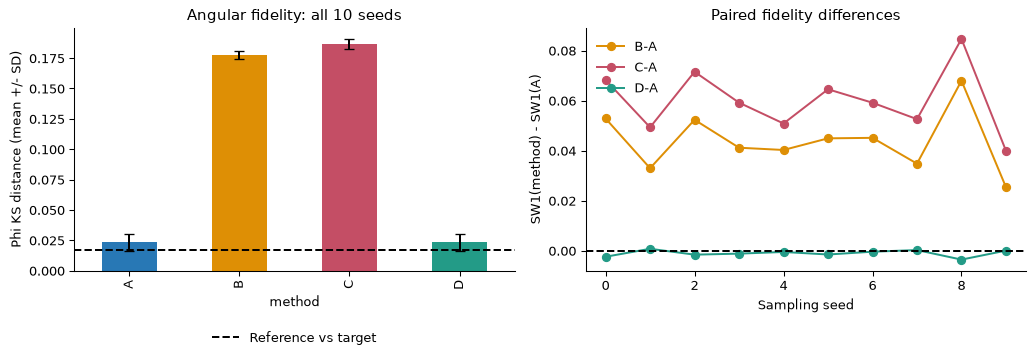

In [8]:
# Display differences paired within each seed. The spread is sampling variability
# for fixed weights, not uncertainty across fitted models.
show_table(paired, "Paired SW1 differences · each sampling seed")
show_table(paired_summary, "Paired SW1 differences · summary across 10 sampling seeds")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
angular_summary.loc[list("ABCD"), "mean"].plot.bar(
    yerr=angular_summary.loc[list("ABCD"), "std"], capsize=4, ax=axes[0], legend=False, color=[COLORS[m] for m in "ABCD"]
)
reference_line = axes[0].axhline(
    angular_summary.loc["reference", "mean"],
    color="black",
    ls="--",
    label="Reference vs target",
)
axes[0].set(
    title="Angular fidelity: all 10 seeds", ylabel="Phi KS distance (mean +/- SD)"
)
axes[0].legend(handles=[reference_line], loc="upper center", bbox_to_anchor=(0.5, -0.20))
for name in paired:
    axes[1].plot(paired.index, paired[name], marker="o", label=name, color=COLORS[name[0]])
axes[1].axhline(0, color="black", ls="--")
axes[1].set(
    title="Paired fidelity differences",
    xlabel="Sampling seed",
    ylabel="SW1(method) - SW1(A)",
)
axes[1].legend()
fig.tight_layout()
fig.savefig(run_dir / "supplementary_metrics.png", dpi=180)
plt.show()

## 5. Interpretation and scope

C and D both achieve numerical feasibility, but C has substantially higher SW1 and angular discrepancy in this setting. The difference is consistent with repeated projection changing the learned trajectory and its final distribution. D preserves fidelity close to A while correcting the endpoint. This is evidence for these weights, constraints and numerical settings, not universal superiority of terminal projection.

Inspect the paired D−A values before describing a small change in fidelity as meaningful. The reference/reference baseline gives a finite-sample scale, not a theoretical lower bound. The figures show **example seed 0**; conclusions use all 10 seeds.

All checkpoints/configuration paths are relative to the project root. The active saved experiment is explicitly identified in `torus_run.json`. Tests import `torus_project.py` directly rather than executing a cell by its numerical index. The separate final technical report includes the supplementary results. The source settings remain those specified in the course materials; no hyperparameter tuning was introduced.